# NTU Datathon 2026 · Track 1 — Smart Campus Analytics
## Predicting campus building energy consumption

**Pipeline** (follows the Workshop #1 baseline, adapted to this dataset):

| Step | What we do | Why |
|---|---|---|
| 1 | Understand the problem | Know the target, the metric and the constraints |
| 2 | Explore the dataset (EDA) | Find which variables actually drive energy usage |
| 3 | Clean & preprocess | Handle missing values so the model never crashes on hidden data |
| 4 | Engineer features | Give the model better clues than the raw columns |
| 5 | Baseline models | Set the bar every later model has to beat |
| 6 | Train & compare models | Linear → Tree → Random Forest → Gradient Boosting → Blend |
| 7 | Evaluate | RMSE, MAE, R² + residual analysis |
| 8 | Final model, `model.pkl`, predictions | Deliverables for the portal |

> Run **Runtime → Restart and run all**. The notebook runs top to bottom in a few minutes.

## 1. Understanding the problem

**Task.** Regression: predict `energy_usage` of a campus building for a given hour, from building information, time, weather, occupancy and the previous usage reading.

**Metrics (60% of Round 1).**
- **RMSE** – squares the errors, so large misses are punished hard. Main metric.
- **MAE** – average absolute miss, in the same units as the target. "On average we are off by X."
- **R²** – share of the variance explained compared with always guessing the mean.

**Constraints that shape our design.**
1. The organisers re-run the submitted `model.pkl` on a **hidden private test set** that "may contain different observations and edge cases". The model must therefore be robust, not just tuned to the public leaderboard.
2. The **test set has far more missing values than the training set** (shown in Step 2). Handling missing data well is the single most important design decision in this notebook.
3. The notebook must run end to end without error, so everything is deterministic (`RANDOM_STATE`) and uses only scikit-learn.

In [1]:
import glob, os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a8a"

### Load the data
The cell searches the current folder (and sub-folders) for the two CSV files, so it works both locally and in Colab once the files are uploaded.

In [2]:
def find(name):
    hits = glob.glob(f"**/{name}", recursive=True) + glob.glob(f"/content/**/{name}", recursive=True)
    assert hits, f"Cannot find '{name}'. Put it next to this notebook (or upload it to Colab)."
    return hits[0]

train = pd.read_csv(find("Track 1 Training Dataset.csv"))
test  = pd.read_csv(find("Track 1 Testing Dataset.csv"))
TARGET = "energy_usage"
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (8000, 11) | test: (3000, 10)


,id,building_id,building_type,hour,day_of_week,month,temperature,humidity,occupancy,previous_usage,energy_usage
0,EC000685,LEC_A,LectureHall,2,Monday,9,25.2,81.9,31.0,28.0,27.2
1,EC003261,SCI_A,Science,1,Wednesday,11,25.7,83.7,14.0,72.6,67.2
2,EC005451,RES_A,Residential,5,Sunday,1,26.3,84.7,199.0,51.6,54.2
3,EC000188,ENG_A,Engineering,21,Wednesday,5,29.1,77.4,68.0,68.3,63.6
4,EC001001,SPT_A,Sports,16,Wednesday,5,30.9,68.2,65.0,49.1,53.9


## 2. Exploring the dataset
*Never skip straight to modelling.* We inspect types, ranges and missing values first, then look at how each feature relates to the target.

In [3]:
train.info()
train.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              8000 non-null   str    
 1   building_id     8000 non-null   str    
 2   building_type   8000 non-null   str    
 3   hour            8000 non-null   int64  
 4   day_of_week     8000 non-null   str    
 5   month           8000 non-null   int64  
 6   temperature     7881 non-null   float64
 7   humidity        7881 non-null   float64
 8   occupancy       7878 non-null   float64
 9   previous_usage  7886 non-null   float64
 10  energy_usage    8000 non-null   float64
dtypes: float64(5), int64(2), str(4)
memory usage: 687.6 KB


,count,mean,std,min,25%,50%,75%,max
hour,8000.0,11.49,6.91,0.0,6.0,11.0,17.0,23.0
month,8000.0,6.54,3.44,1.0,4.0,7.0,10.0,12.0
temperature,7881.0,28.22,1.88,23.2,26.8,28.2,29.6,35.8
humidity,7881.0,78.05,5.57,61.1,74.3,78.0,81.7,100.0
occupancy,7878.0,72.58,74.33,0.0,8.0,42.0,129.0,337.0
previous_usage,7886.0,49.67,18.94,5.3,35.9,46.4,61.4,149.4
energy_usage,8000.0,51.25,18.45,13.2,38.0,48.1,62.7,143.9


**Columns**

| Column | Meaning | Type |
|---|---|---|
| `id` | Row identifier (not a feature) | text |
| `building_id` / `building_type` | Which building, and its category (12 buildings, 8 types) | categorical |
| `hour`, `day_of_week`, `month` | When the reading was taken | time |
| `temperature`, `humidity` | Weather | numeric |
| `occupancy` | People in the building | numeric |
| `previous_usage` | Energy usage at the previous reading | numeric |
| `energy_usage` | **Target** | numeric |

There is no timestamp and the rows are shuffled, so – unlike the theme-park workshop – we cannot split by date. A shuffled **K-fold cross-validation** is the correct validation scheme here.

### 2.1 Missing values — train vs test

In [3]:
miss = pd.DataFrame({"train %": train.isna().mean()*100, "test %": test.isna().mean()*100}).round(2)
miss = miss[(miss.fillna(0) > 0).any(axis=1)]
display(miss)

ax = miss.plot.bar(color=[BLUE, ORANGE], figsize=(7, 3.2), rot=0)
ax.set_ylabel("% missing"); ax.set_title("Missing values: the test set has ~5x more than training")
plt.show()

cols = list(miss.index)
print(f"Rows with at least one missing value: train {train[cols].isna().any(axis=1).mean()*100:.1f}%"
      f"  |  test {test[cols].isna().any(axis=1).mean()*100:.1f}%")

NameError: name 'pd' is not defined

**Key finding.** Only ~1.5% of each numeric column is missing in training, but ~6–7% in test. A model that has barely seen missing values during training will be weak exactly where the test set is different. We address this in Step 3 and Step 5 (missing-value augmentation).

### 2.2 Target distribution and the main relationships

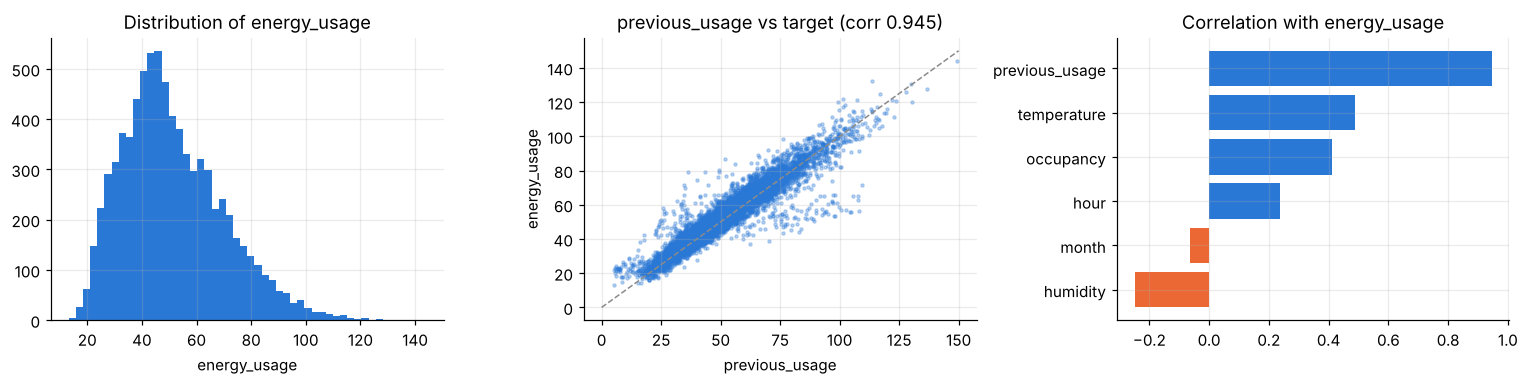

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(train[TARGET], bins=50, color=BLUE); ax[0].set_title("Distribution of energy_usage"); ax[0].set_xlabel("energy_usage")

m = train.previous_usage.notna()
ax[1].scatter(train.previous_usage[m], train[TARGET][m], s=4, alpha=.3, color=BLUE)
lim = [0, 150]; ax[1].plot(lim, lim, color=GREY, lw=1, ls="--")
ax[1].set_title(f"previous_usage vs target (corr {train.previous_usage.corr(train[TARGET]):.3f})")
ax[1].set_xlabel("previous_usage"); ax[1].set_ylabel("energy_usage")

corr = train.select_dtypes("number").corr()[TARGET].drop(TARGET).sort_values()
ax[2].barh(corr.index, corr.values, color=[ORANGE if v < 0 else BLUE for v in corr.values])
ax[2].set_title("Correlation with energy_usage")
plt.tight_layout(); plt.show()

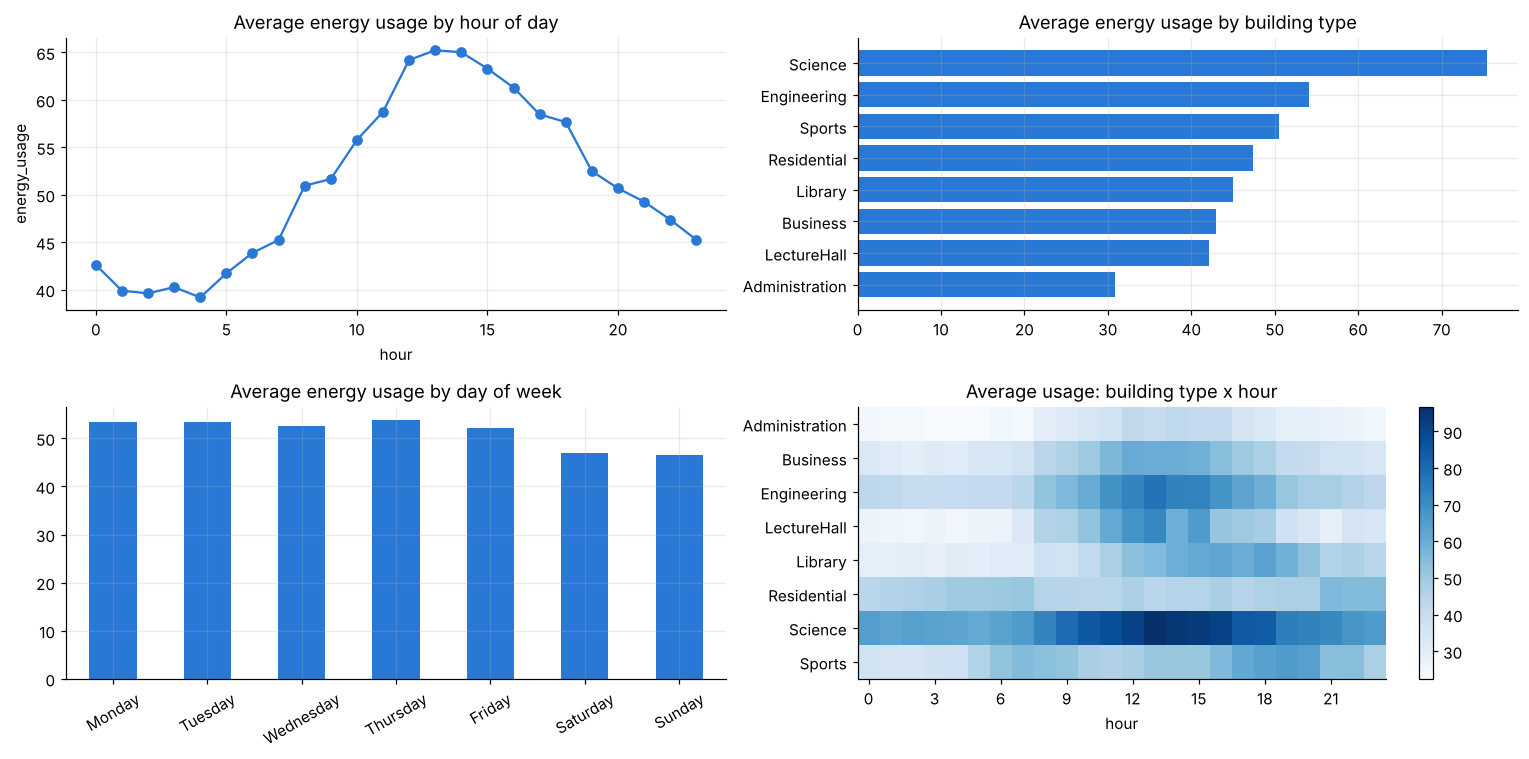

In [6]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
fig, ax = plt.subplots(2, 2, figsize=(14, 7))

train.groupby("hour")[TARGET].mean().plot(ax=ax[0,0], marker="o", color=BLUE)
ax[0,0].set_title("Average energy usage by hour of day"); ax[0,0].set_ylabel("energy_usage")

bt = train.groupby("building_type")[TARGET].mean().sort_values()
ax[0,1].barh(bt.index, bt.values, color=BLUE); ax[0,1].set_title("Average energy usage by building type")

train.groupby("day_of_week")[TARGET].mean().reindex(order).plot.bar(ax=ax[1,0], color=BLUE, rot=30)
ax[1,0].set_title("Average energy usage by day of week"); ax[1,0].set_xlabel("")

piv = train.pivot_table(index="building_type", columns="hour", values=TARGET, aggfunc="mean")
im = ax[1,1].imshow(piv.values, aspect="auto", cmap="Blues")
ax[1,1].set_yticks(range(len(piv.index))); ax[1,1].set_yticklabels(piv.index)
ax[1,1].set_xticks(range(0, 24, 3)); ax[1,1].set_xlabel("hour"); ax[1,1].grid(False)
ax[1,1].set_title("Average usage: building type x hour"); plt.colorbar(im, ax=ax[1,1])
plt.tight_layout(); plt.show()

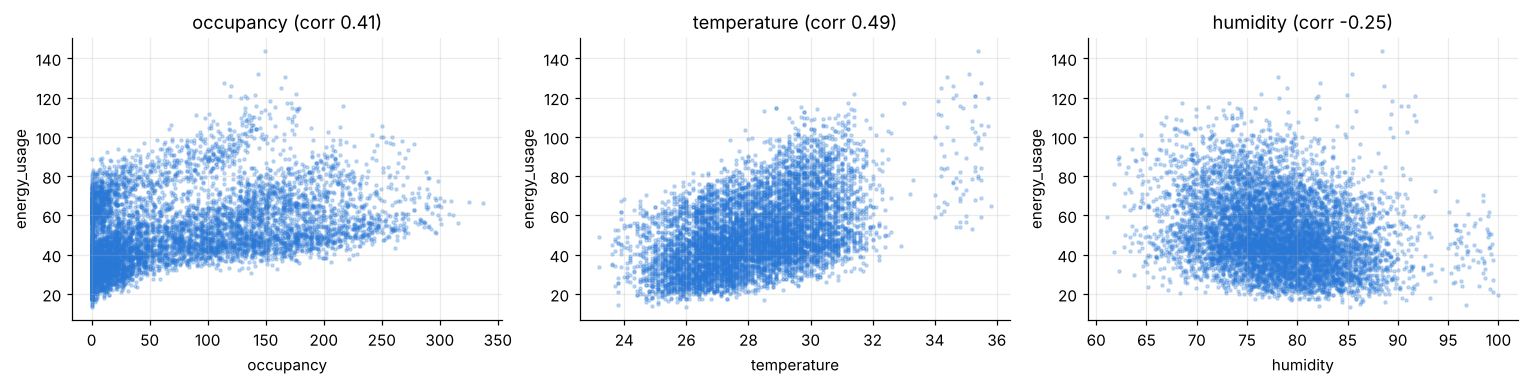

weekend,weekday mean,weekend mean
building_type,,
Administration,32.7,25.8
Business,46.4,34.7
Engineering,56.3,48.2
LectureHall,45.0,35.8
Library,44.6,46.0
Residential,47.2,48.1
Science,77.4,69.9
Sports,49.9,51.7


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, c in zip(ax, ["occupancy", "temperature", "humidity"]):
    a.scatter(train[c], train[TARGET], s=4, alpha=.25, color=BLUE)
    a.set_xlabel(c); a.set_ylabel("energy_usage"); a.set_title(f"{c} (corr {train[c].corr(train[TARGET]):.2f})")
plt.tight_layout(); plt.show()

wk = train.assign(weekend=train.day_of_week.isin(["Saturday","Sunday"]))
display(wk.pivot_table(index="building_type", columns="weekend", values=TARGET, aggfunc="mean").round(1)
          .rename(columns={False:"weekday mean", True:"weekend mean"}))

**What the EDA tells us**

1. **`previous_usage` is the star feature** (correlation ≈ 0.95). What happened at the last reading largely dictates the current one – the same role `previous_wait_minutes` played in the workshop.
2. **Building type sets the level.** Science buildings use far more than Administration. The model must know which building it is looking at.
3. **Hour matters and is cyclical.** Usage rises through the working day and falls at night; hour 23 and hour 0 are neighbours.
4. **The daily shape differs by building type** (heat-map), so *interactions* matter – tree models find them automatically.
5. **Occupancy and temperature push usage up; humidity is weakly negative** (it is mostly a proxy for night-time).
6. **Weekday vs weekend**: compare the two columns of the table above per building type.

## 3. Cleaning and preprocessing

**Checks first:** duplicates, impossible values, and categories in test that never appear in train.

In [8]:
print("duplicate ids in train:", train.id.duplicated().sum())
print("building_ids only in test:", set(test.building_id) - set(train.building_id))
print("hour range:", train.hour.min(), "-", train.hour.max(), "| month range:", train.month.min(), "-", train.month.max())
print("negative values:", {c: int((train[c] < 0).sum()) for c in ["occupancy", "previous_usage", TARGET]})

duplicate ids in train: 0
building_ids only in test: set()
hour range: 0 - 23 | month range: 1 - 12
negative values: {'occupancy': 0, 'previous_usage': 0, 'energy_usage': 0}


The data is clean apart from the missing values, so no rows are dropped.

**How we handle missing values** (the workshop used `.fillna(median)`; we go one step further):

- **Missing-value flags** (`<col>_missing`): we record *that* a value was missing, so the model can react to it.
- **Tree / boosting models** receive the `NaN` as it is. `HistGradientBoostingRegressor` handles `NaN` natively: at each split it learns which side missing values should go to. When `previous_usage` is missing it automatically falls back on building, hour and occupancy.
- **Linear models** cannot take `NaN`, so inside their pipeline a `SimpleImputer(median)` fills the holes. The median is learned on the training data only (no leakage).
- **Categorical columns** are one-hot encoded with `handle_unknown="ignore"`, so an unseen building in the hidden test set cannot crash the model.

Everything that *learns* something from data lives inside a scikit-learn `Pipeline`. This guarantees the same treatment in cross-validation, on the test set, and when the organisers load `model.pkl`.

## 4. Feature engineering

`engineer()` is a **stateless** function: it only uses the values of the row itself, so it can be copied as-is into the prediction notebook that loads `model.pkl` (as the submission instructions require).

| Feature | Idea |
|---|---|
| `hour_sin`, `hour_cos`, `month_sin`, `month_cos` | Cyclical encoding – 23:00 and 00:00 become neighbours |
| `is_weekend` | Weekend behaviour differs for teaching buildings |
| `is_working_hours` | 08:00–18:00, the busy block seen in the hour chart |
| `is_night` | 00:00–05:00, base-load only |
| `occ_x_weekend`, `occ_x_working` | Same crowd means something different on a weekend / at night |
| `temp_x_occ` | Cooling load: hot **and** full is worse than either alone |
| `discomfort` | Temperature combined with humidity (air-conditioning demand) |
| `*_missing` | Flags for missing numeric values |

In [9]:
NUM_RAW = ["temperature", "humidity", "occupancy", "previous_usage"]
CAT = ["building_id", "building_type", "day_of_week"]

def engineer(df):
    X = df.drop(columns=["id", TARGET], errors="ignore").copy()
    for c in NUM_RAW:
        X[c + "_missing"] = X[c].isna().astype(int)
    X["hour_sin"]  = np.sin(2*np.pi*X["hour"]/24);  X["hour_cos"]  = np.cos(2*np.pi*X["hour"]/24)
    X["month_sin"] = np.sin(2*np.pi*X["month"]/12); X["month_cos"] = np.cos(2*np.pi*X["month"]/12)
    X["is_weekend"] = X["day_of_week"].isin(["Saturday", "Sunday"]).astype(int)
    X["is_working_hours"] = X["hour"].between(8, 18).astype(int)
    X["is_night"] = (X["hour"] <= 5).astype(int)
    X["occ_x_weekend"] = X["occupancy"] * X["is_weekend"]
    X["occ_x_working"] = X["occupancy"] * X["is_working_hours"]
    X["temp_x_occ"] = X["temperature"] * X["occupancy"]
    X["discomfort"] = X["temperature"] * X["humidity"] / 100
    return X

X_all = engineer(train)
y_all = train[TARGET].values
NUM = [c for c in X_all.columns if c not in CAT]
print(X_all.shape[1], "features"); X_all.head(3)

24 features


,building_id,building_type,hour,day_of_week,month,temperature,humidity,occupancy,previous_usage,temperature_missing,...,hour_cos,month_sin,month_cos,is_weekend,is_working_hours,is_night,occ_x_weekend,occ_x_working,temp_x_occ,discomfort
0,LEC_A,LectureHall,2,Monday,9,25.2,81.9,31.0,28.0,0,...,0.866025,-1.0,-1.836970e-16,0,0,1,0.0,0.0,781.2,20.6388
1,SCI_A,Science,1,Wednesday,11,25.7,83.7,14.0,72.6,0,...,0.965926,-0.5,8.660254e-01,0,0,1,0.0,0.0,359.8,21.5109
2,RES_A,Residential,5,Sunday,1,26.3,84.7,199.0,51.6,0,...,0.258819,0.5,8.660254e-01,1,0,1,199.0,0.0,5233.7,22.2761


### Model builders
Each model is a `Pipeline`: one-hot encoding of the categorical columns, then the regressor. Models that cannot take `NaN` get a median imputer (and a scaler for the linear model).

In [10]:
def onehot():
    return OneHotEncoder(handle_unknown="ignore")

def prep_keep_nan():      # for gradient boosting: NaN passed through
    return ColumnTransformer([("cat", onehot(), CAT)], remainder="passthrough", sparse_threshold=0)

def prep_impute(scale=False):   # for linear / tree / forest
    steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("cat", onehot(), CAT), ("num", Pipeline(steps), NUM)], sparse_threshold=0)

def make_dummy():  return DummyRegressor(strategy="mean")
def make_linear(): return Pipeline([("prep", prep_impute(scale=True)), ("reg", LinearRegression())])
def make_ridge():  return Pipeline([("prep", prep_impute(scale=True)), ("reg", Ridge(alpha=1.0))])
def make_tree():   return Pipeline([("prep", prep_impute()), ("reg", DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE))])
def make_forest(): return Pipeline([("prep", prep_impute()), ("reg", RandomForestRegressor(n_estimators=180, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))])

HGB_PARAMS = dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=31, l2_regularization=1.0)
def make_hgb(**kw):
    return Pipeline([("prep", prep_keep_nan()),
                     ("reg", HistGradientBoostingRegressor(random_state=RANDOM_STATE, **{**HGB_PARAMS, **kw}))])
def make_blend(w=(0.7, 0.3)):
    return VotingRegressor([("hgb", make_hgb()), ("ridge", make_ridge())], weights=list(w))

## 5. Validation scheme and baselines

### How we validate
- **5-fold cross-validation**: the training set is split in 5 parts; each part is predicted by a model trained on the other 4. Every row is predicted exactly once by a model that never saw it, which gives a more reliable score than one single split.
- We report **two scores** for every model:
  - **CV (clean)** – validation folds as they are (≈1.5% missing).
  - **CV (test-like)** – the same folds, but with extra values blanked out at random so the missing rate matches the **test set**. This is our best estimate of the leaderboard score.

### Missing-value augmentation (`augment=k`)
The model sees too few missing values during training. With `augment=k` we add `k` extra copies of the **training fold** in which values are blanked at random at the test-set rate. The targets are unchanged. The model learns "what to predict when `previous_usage` is unavailable" from thousands of examples instead of ~100. The validation fold is never augmented, so the score stays honest.

In [11]:
TEST_MISS = test[NUM_RAW].isna().mean()           # per-column missing rate in the test set
TRAIN_MISS = train[NUM_RAW].isna().mean()
EXTRA = ((TEST_MISS - TRAIN_MISS) / (1 - TRAIN_MISS)).clip(lower=0)
print("extra masking rate needed to look like test:", EXTRA.round(3).to_dict())

def mask_like_test(df, seed, rates=None):
    # Blank numeric values at random. Default rate makes the result match the test-set missing rate.
    rates = EXTRA if rates is None else rates
    rng = np.random.RandomState(seed); out = df.copy()
    for c in NUM_RAW:
        out.loc[rng.rand(len(out)) < rates[c], c] = np.nan
    return out

def augment_rows(df, y, k):
    # Original rows + k masked copies (masked at the full test-set rate).
    if k == 0: return df, y
    parts = [df] + [mask_like_test(df, seed=1000 + i, rates=TEST_MISS) for i in range(k)]
    return pd.concat(parts, ignore_index=True), np.tile(y, k + 1)

def metrics(y, p):
    return dict(RMSE=mean_squared_error(y, p) ** 0.5, MAE=mean_absolute_error(y, p), R2=r2_score(y, p))

def cv_eval(make_model, augment=0, n_splits=5):
    # Returns (clean metrics, test-like metrics, out-of-fold predictions on clean / test-like rows).
    oof, oof_m = np.zeros(len(train)), np.zeros(len(train))
    kf = KFold(n_splits, shuffle=True, random_state=RANDOM_STATE)
    for i, (tr_idx, va_idx) in enumerate(kf.split(train)):
        df_tr, y_tr = augment_rows(train.iloc[tr_idx], y_all[tr_idx], augment)
        model = make_model().fit(engineer(df_tr), y_tr)
        oof[va_idx]   = model.predict(engineer(train.iloc[va_idx]))
        oof_m[va_idx] = model.predict(engineer(mask_like_test(train.iloc[va_idx], seed=i)))
    return metrics(y_all, oof), metrics(y_all, oof_m), oof, oof_m

results, oofs = {}, {}
def record(name, clean, like):
    results[name] = {"RMSE (clean)": clean["RMSE"], "MAE (clean)": clean["MAE"], "R2 (clean)": clean["R2"],
                     "RMSE (test-like)": like["RMSE"], "MAE (test-like)": like["MAE"], "R2 (test-like)": like["R2"]}
    print(f"{name:34s} clean RMSE {clean['RMSE']:.3f} | test-like RMSE {like['RMSE']:.3f} MAE {like['MAE']:.3f} R2 {like['R2']:.4f}")

def run(name, make_model, augment=0):
    clean, like, oof, oof_m = cv_eval(make_model, augment)
    oofs[name] = (oof, oof_m); record(name, clean, like)

extra masking rate needed to look like test: {'temperature': 0.056, 'humidity': 0.047, 'occupancy': 0.054, 'previous_usage': 0.054}


### Baselines
Two "lazy" baselines set the bar:
- **Mean** – always predict the average usage (this is the R² = 0 reference).
- **Persistence** – predict `energy_usage = previous_usage` (when missing, use the mean). No machine learning at all. Any model worth submitting must beat this.

In [12]:
run("0a. Baseline: mean", make_dummy)

fill = train.previous_usage.mean()
pers = train.previous_usage.fillna(fill).values
pers_m = np.zeros(len(train))
for i, (_, va) in enumerate(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(train)):
    pers_m[va] = mask_like_test(train.iloc[va], seed=i).previous_usage.fillna(fill).values
record("0b. Baseline: persistence", metrics(y_all, pers), metrics(y_all, pers_m))

0a. Baseline: mean                 clean RMSE 18.449 | test-like RMSE 18.449 MAE 14.750 R2 -0.0001
0b. Baseline: persistence          clean RMSE 6.714 | test-like RMSE 7.936 MAE 5.039 R2 0.8150


## 6. Train and compare models

We climb the same ladder as the workshop and add one more rung.

| Model | Idea | Assumptions / weakness |
|---|---|---|
| **Linear regression** | Each feature adds or removes a fixed amount | Effects are additive and straight-line; sensitive to outliers; needs imputation |
| **Decision tree** | A sequence of yes/no questions | No assumption on shape, but unstable and cannot predict outside the range it has seen |
| **Random forest** | Average of 180 trees trained on random samples | More stable than one tree; still cannot extrapolate; predictions are averages so peaks get flattened |
| **Gradient boosting** (`HistGradientBoostingRegressor`) | Trees built one after another, each correcting the errors of the previous ones | Captures curves and interactions, handles `NaN` natively; needs tuning to avoid over-fitting |
| **Blend** (boosting + ridge) | Weighted average of the two | Boosting captures interactions, the linear part captures the strong straight-line link with `previous_usage` and can extrapolate |

In [13]:
run("1. Linear regression", make_linear)
run("2. Decision tree (depth 8)", make_tree)
run("3. Random forest (180 trees)", make_forest)
run("4. Gradient boosting", make_hgb)
run("5. Gradient boosting + augment", make_hgb, augment=4)

1. Linear regression               clean RMSE 3.787 | test-like RMSE 4.611 MAE 3.359 R2 0.9375


2. Decision tree (depth 8)         clean RMSE 4.739 | test-like RMSE 5.454 MAE 3.938 R2 0.9126


3. Random forest (180 trees)       clean RMSE 3.997 | test-like RMSE 4.523 MAE 3.317 R2 0.9399


4. Gradient boosting               clean RMSE 3.519 | test-like RMSE 3.894 MAE 2.944 R2 0.9554


5. Gradient boosting + augment     clean RMSE 3.488 | test-like RMSE 3.637 MAE 2.812 R2 0.9611


### 6.1 Hyper-parameter check for gradient boosting
A small, readable grid instead of a huge search. We compare a few settings of tree size (`max_leaf_nodes`), learning rate / number of trees and regularisation, scored on the **test-like** RMSE with augmentation.

In [14]:
grid = [
    dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=31, l2_regularization=1.0),   # current choice (HGB_PARAMS)
    dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=15, l2_regularization=1.0),
    dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=63, l2_regularization=1.0),
    dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=7,  l2_regularization=1.0),
    dict(learning_rate=0.02, max_iter=1000, max_leaf_nodes=31, l2_regularization=1.0),
    dict(learning_rate=0.08, max_iter=300, max_leaf_nodes=31, l2_regularization=1.0),
    dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=31, l2_regularization=10.0),
    dict(learning_rate=0.04, max_iter=500, max_leaf_nodes=31, l2_regularization=1.0, min_samples_leaf=40),
]
rows = []
for g in grid:
    clean, like, _, _ = cv_eval(lambda g=g: make_hgb(**g), augment=4)
    rows.append({**g, "RMSE clean": round(clean["RMSE"], 4), "RMSE test-like": round(like["RMSE"], 4)})
tune = pd.DataFrame(rows).sort_values("RMSE test-like")
tune["min_samples_leaf"] = tune["min_samples_leaf"].fillna(20).astype(int)   # 20 = sklearn default
display(tune)

,learning_rate,max_iter,max_leaf_nodes,l2_regularization,RMSE clean,RMSE test-like,min_samples_leaf
7,0.04,500,31,1.0,3.4703,3.6224,40
4,0.02,1000,31,1.0,3.4835,3.6333,20
6,0.04,500,31,10.0,3.4806,3.6345,20
0,0.04,500,31,1.0,3.4879,3.6373,20
5,0.08,300,31,1.0,3.5031,3.6531,20
2,0.04,500,63,1.0,3.5160,3.6604,20
1,0.04,500,15,1.0,3.5269,3.6921,20
3,0.04,500,7,1.0,3.6070,3.7915,20


If the differences between settings are small (a few hundredths of RMSE), the model is **not sensitive to tuning** – a good sign for the hidden test set. `HGB_PARAMS` is the first row of the grid list (marked *current choice*); it was chosen from this comparison. If another row is clearly better in your run, copy its values into `HGB_PARAMS` above and re-run.

### 6.2 Blend weight
We reuse the out-of-fold predictions of boosting and ridge (both trained with augmentation) and try every weight from 0 to 1.

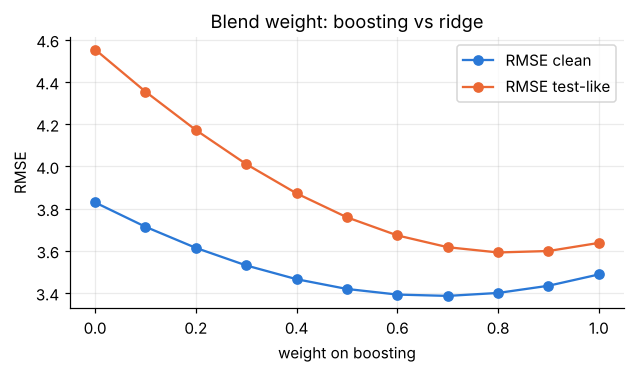

best weight on boosting (test-like): 0.8
6. Blend (HGB+Ridge) + augment     clean RMSE 3.400 | test-like RMSE 3.592 MAE 2.775 R2 0.9621


In [15]:
h_oof, h_oof_m = oofs["5. Gradient boosting + augment"]
_, _, r_oof, r_oof_m = cv_eval(make_ridge, augment=4)
ws = np.round(np.linspace(0, 1, 11), 1)
bl = pd.DataFrame({"weight on boosting": ws,
                   "RMSE clean":     [mean_squared_error(y_all, w*h_oof   + (1-w)*r_oof)   ** .5 for w in ws],
                   "RMSE test-like": [mean_squared_error(y_all, w*h_oof_m + (1-w)*r_oof_m) ** .5 for w in ws]})
ax = bl.plot(x="weight on boosting", marker="o", figsize=(6.5, 3.2), color=[BLUE, ORANGE])
ax.set_ylabel("RMSE"); ax.set_title("Blend weight: boosting vs ridge"); plt.show()
BEST_W = float(bl.loc[bl["RMSE test-like"].idxmin(), "weight on boosting"])
print("best weight on boosting (test-like):", BEST_W)

BEST = "6. Blend (HGB+Ridge) + augment"
oofs[BEST] = (BEST_W*h_oof + (1-BEST_W)*r_oof, BEST_W*h_oof_m + (1-BEST_W)*r_oof_m)
record(BEST, metrics(y_all, oofs[BEST][0]), metrics(y_all, oofs[BEST][1]))

## 7. Evaluate performance

,RMSE (clean),MAE (clean),R2 (clean),RMSE (test-like),MAE (test-like),R2 (test-like)
0a. Baseline: mean,18.4487,14.7505,-0.0001,18.4487,14.7505,-0.0001
0b. Baseline: persistence,6.7136,4.4623,0.8676,7.9356,5.0395,0.8150
1. Linear regression,3.7871,2.9026,0.9579,4.6108,3.3592,0.9375
2. Decision tree (depth 8),4.7387,3.5713,0.9340,5.4537,3.9381,0.9126
3. Random forest (180 trees),3.9966,3.0373,0.9531,4.5234,3.3167,0.9399
4. Gradient boosting,3.5191,2.7330,0.9636,3.8939,2.9440,0.9554
5. Gradient boosting + augment,3.4879,2.7163,0.9643,3.6373,2.8119,0.9611
6. Blend (HGB+Ridge) + augment,3.4001,2.6533,0.9660,3.5920,2.7747,0.9621


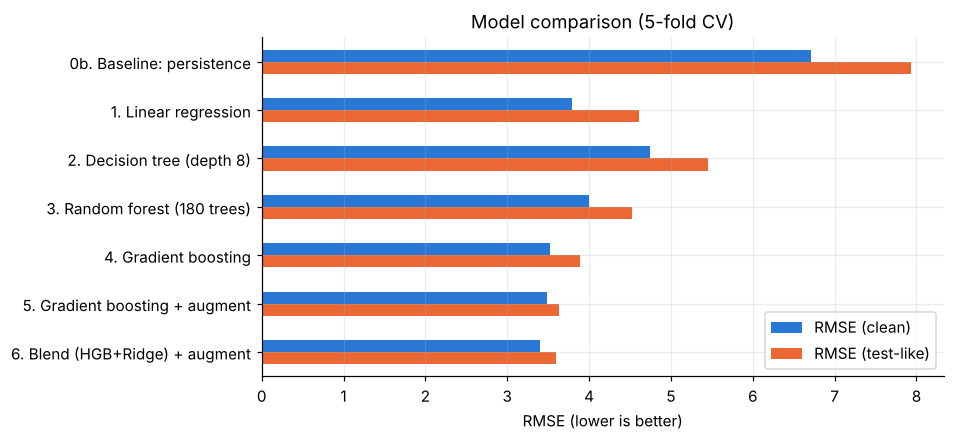

In [16]:
res = pd.DataFrame(results).T
display(res.round(4))

ax = res[["RMSE (clean)", "RMSE (test-like)"]].iloc[1:].plot.barh(figsize=(8, 4), color=[BLUE, ORANGE])
ax.invert_yaxis(); ax.set_xlabel("RMSE (lower is better)"); ax.set_title("Model comparison (5-fold CV)"); plt.show()

**How to read the table**

- Every model beats both baselines by a wide margin, so the pipeline is doing real work.
- **Linear regression is already strong** – the relationship is dominated by the near-linear link with `previous_usage`. That is why a "simple" model belongs in the blend.
- **Random forest does not clearly beat linear regression here.** Forests average, which flattens the peaks, and they cannot extrapolate along `previous_usage`.
- **Gradient boosting is the best single model**; it picks up the building × hour × occupancy interactions.
- **Augmentation barely changes the clean score but improves the test-like score** – exactly the rows that make the test set different.
- **RMSE vs MAE:** RMSE is only moderately larger than MAE, so errors are fairly uniform with a small number of large misses (see residuals below).

### 7.1 Residual analysis of the selected model

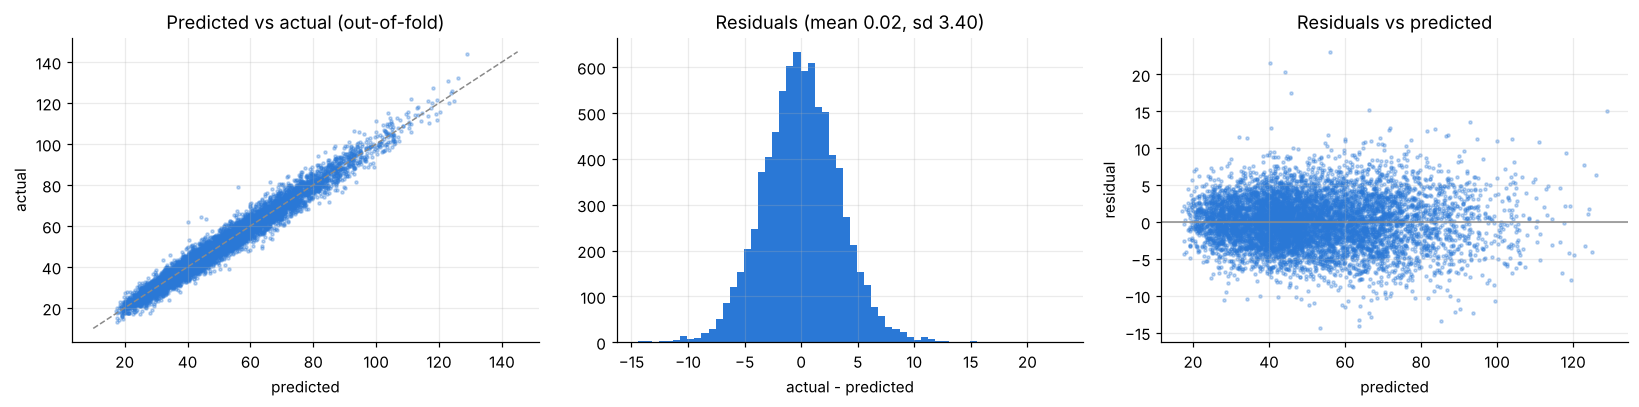

,RMSE,MAE,rows
type,,,
Administration,2.79,2.23,516
Library,3.14,2.46,710
Business,3.16,2.46,1354
Residential,3.21,2.55,1197
LectureHall,3.31,2.56,785
Engineering,3.40,2.68,1457
Sports,3.71,2.85,558
Science,3.98,3.11,1423


test-like RMSE | previous_usage present: 3.462 | previous_usage missing: 5.041  (6.9% of rows)
same missing rows, boosting WITHOUT augmentation (model 4): 6.760
rows with |error| > 15: 6 (0.07%), carrying 2.4% of the squared error


In [17]:
oof, oof_m = oofs[BEST]; resid = y_all - oof

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].scatter(oof, y_all, s=4, alpha=.3, color=BLUE); ax[0].plot([10, 145], [10, 145], color=GREY, ls="--", lw=1)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("actual"); ax[0].set_title("Predicted vs actual (out-of-fold)")
ax[1].hist(resid, bins=60, color=BLUE); ax[1].set_title(f"Residuals (mean {resid.mean():.2f}, sd {resid.std():.2f})"); ax[1].set_xlabel("actual - predicted")
ax[2].scatter(oof, resid, s=4, alpha=.3, color=BLUE); ax[2].axhline(0, color=GREY, lw=1)
ax[2].set_xlabel("predicted"); ax[2].set_ylabel("residual"); ax[2].set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

by_type = (pd.DataFrame({"type": train.building_type, "sq": resid**2, "ab": np.abs(resid)}).groupby("type")
             .agg(RMSE=("sq", lambda s: s.mean()**.5), MAE=("ab", "mean"), rows=("sq", "size")))
display(by_type.round(2).sort_values("RMSE"))

# Error on rows where previous_usage is missing (in the test-like version of each fold)
masked_prev = np.zeros(len(train), bool)
for i, (_, va) in enumerate(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(train)):
    masked_prev[va] = mask_like_test(train.iloc[va], seed=i).previous_usage.isna().values
rm = lambda p, m: mean_squared_error(y_all[m], p[m]) ** .5
print(f"test-like RMSE | previous_usage present: {rm(oof_m, ~masked_prev):.3f} | previous_usage missing: {rm(oof_m, masked_prev):.3f}  ({masked_prev.mean()*100:.1f}% of rows)")
print(f"same missing rows, boosting WITHOUT augmentation (model 4): {rm(oofs['4. Gradient boosting'][1], masked_prev):.3f}")
big = np.abs(resid) > 15
print(f"rows with |error| > 15: {big.sum()} ({big.mean()*100:.2f}%), carrying {((resid[big]**2).sum()/(resid**2).sum())*100:.1f}% of the squared error")

**Reading the residuals**
- Points sit on the diagonal and residuals are centred on zero: no systematic over- or under-prediction.
- Error differs by building type – larger where usage is higher and more variable.
- Rows where `previous_usage` is missing are much harder – unavoidable, because the star feature is gone – and augmentation reduces that error.
- A handful of rows have very large errors. These look like abrupt jumps that no available feature explains; we deliberately do **not** over-fit to them.

### 7.2 Which information matters? (permutation importance)
We shuffle one **original** column at a time on a held-out 20% and measure how much RMSE gets worse. Shuffling the raw column (and rebuilding the engineered features from it) gives the true importance of each piece of information.

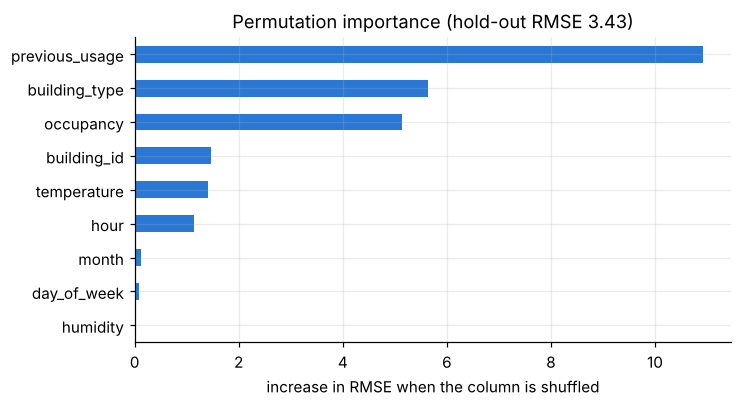

previous_usage    10.922
building_type      5.628
occupancy          5.137
building_id        1.476
temperature        1.416
hour               1.147
month              0.121
day_of_week        0.083
humidity           0.008


In [18]:
df_tr, df_va = train_test_split(train, test_size=0.2, random_state=RANDOM_STATE)
a_df, a_y = augment_rows(df_tr, df_tr[TARGET].values, 4)
m_imp = make_blend((BEST_W, 1 - BEST_W)).fit(engineer(a_df), a_y)
base_rmse = mean_squared_error(df_va[TARGET], m_imp.predict(engineer(df_va))) ** .5
rng = np.random.RandomState(RANDOM_STATE); imp = {}
for col in [c for c in train.columns if c not in ("id", TARGET)]:
    inc = []
    for _ in range(5):
        s = df_va.copy(); s[col] = rng.permutation(s[col].values)
        inc.append(mean_squared_error(df_va[TARGET], m_imp.predict(engineer(s))) ** .5 - base_rmse)
    imp[col] = np.mean(inc)
imp = pd.Series(imp).sort_values()
ax = imp.plot.barh(color=BLUE, figsize=(7, 3.6)); ax.set_xlabel("increase in RMSE when the column is shuffled")
ax.set_title(f"Permutation importance (hold-out RMSE {base_rmse:.2f})"); plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

## 8. Final model, `model.pkl` and predictions

**Selected model: weighted blend of gradient boosting and ridge regression, trained with missing-value augmentation.**

Why this model:
1. Best cross-validated RMSE / MAE / R², on both the clean and the test-like evaluation.
2. Robust to the test set's higher missing rate (native `NaN` handling + augmentation + missing flags).
3. Two members with *different* assumptions – additive/linear and tree-based – so their errors partly cancel.
4. Only scikit-learn components, so `model.pkl` loads anywhere with `pickle` and no custom classes.

**Assumptions and limitations**
- Hidden test rows come from the same buildings, seasons and operating conditions as training (unseen buildings are tolerated but predicted less accurately).
- Values are assumed missing at random; if they are missing for a systematic reason (e.g. sensor fails at high load) the error on those rows will be higher.
- Rows are treated as independent – there is no timestamp, so we cannot build longer lag features.
- Sudden jumps not reflected in any feature cannot be predicted.

We now retrain on **all** training rows (with augmentation) and save the model.

In [19]:
full_df, full_y = augment_rows(train, y_all, 4)
final_model = make_blend((BEST_W, 1 - BEST_W)).fit(engineer(full_df), full_y)

with open("model.pkl", "wb") as f:
    pickle.dump(final_model, f)
print("saved model.pkl", round(os.path.getsize("model.pkl") / 1e6, 2), "MB")

saved model.pkl 1.81 MB


### Predict the test set
Exactly the steps the organisers describe: copy `engineer()`, load `model.pkl`, predict, save to CSV. We reload the pickle here to prove the saved file works.

> **Check the portal for the exact CSV format.** This cell writes `id, energy_usage`. Change `ID_COL` / `PRED_COL` if the portal asks for different column names.

In [20]:
ID_COL, PRED_COL = "id", "energy_usage"

with open("model.pkl", "rb") as f:
    loaded = pickle.load(f)

pred = loaded.predict(engineer(test))
submission = pd.DataFrame({ID_COL: test["id"], PRED_COL: np.round(pred, 2)})

assert len(submission) == len(test), "wrong number of rows"
assert submission[PRED_COL].notna().all(), "NaN in predictions"
assert np.allclose(pred, final_model.predict(engineer(test))), "pickle round-trip mismatch"
submission.to_csv("submission.csv", index=False)

print(submission.shape); display(submission.head())
print(pd.DataFrame({"test predictions": submission[PRED_COL].describe(), "training target": train[TARGET].describe()}).round(2).to_string())

(3000, 2)


,id,energy_usage
0,EC010541,71.84
1,EC009755,67.02
2,EC008886,55.26
3,EC009317,64.88
4,EC008958,21.86


       test predictions  training target
count           3000.00          8000.00
mean              54.56            51.25
std               20.04            18.45
min               15.95            13.20
25%               40.40            38.00
50%               52.93            48.10
75%               67.46            62.70
max              126.86           143.90


### Optional: one submission file per model
To check each model on the public leaderboard, this cell trains every candidate on the full training set and writes one CSV per model into `submissions/`. Compare the leaderboard score with the **test-like CV** column of the table in Step 7 – if they agree, our validation can be trusted for the private test set.

In [21]:
os.makedirs("submissions", exist_ok=True)
candidates = {
    "1_linear":                (make_linear, 0),
    "2_decision_tree":         (make_tree, 0),
    "3_random_forest":         (make_forest, 0),
    "4_gradient_boosting":     (make_hgb, 0),
    "5_gradient_boosting_aug": (make_hgb, 4),
    "6_blend_aug_FINAL":       (lambda: make_blend((BEST_W, 1 - BEST_W)), 4),
}
Xte = engineer(test)
for name, (mk, k) in candidates.items():
    d, yy = augment_rows(train, y_all, k)
    p = mk().fit(engineer(d), yy).predict(Xte)
    pd.DataFrame({ID_COL: test["id"], PRED_COL: np.round(p, 2)}).to_csv(f"submissions/{name}.csv", index=False)
    print(f"submissions/{name}.csv   mean prediction {p.mean():.2f}")

submissions/1_linear.csv   mean prediction 54.67


submissions/2_decision_tree.csv   mean prediction 54.53


submissions/3_random_forest.csv   mean prediction 54.44


submissions/4_gradient_boosting.csv   mean prediction 54.65


submissions/5_gradient_boosting_aug.csv   mean prediction 54.57


submissions/6_blend_aug_FINAL.csv   mean prediction 54.56


### Requirements file

In [22]:
import sklearn, matplotlib
req = f"numpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\nmatplotlib=={matplotlib.__version__}\n"
with open("requirements.txt", "w") as f:
    f.write(req)
print(req)

numpy==2.5.3
pandas==3.0.5
scikit-learn==1.9.1
matplotlib==3.11.2



## Summary

| | |
|---|---|
| **Problem** | Regression of hourly building `energy_usage` |
| **Key data insight** | `previous_usage` dominates; building type sets the level; test set has ~5x more missing values than train |
| **Preprocessing** | Missing flags, native `NaN` handling (boosting), median imputation inside the pipeline (linear), one-hot with unknown-category protection |
| **Features** | Cyclical hour/month, weekend / working-hours / night flags, occupancy and temperature interactions |
| **Validation** | 5-fold CV, reported on clean folds and on folds masked to match the test set |
| **Model** | Blend of gradient boosting and ridge, trained with missing-value augmentation |
| **Outputs** | `model.pkl`, `submission.csv`, `submissions/*.csv`, `requirements.txt` |

**Possible improvements with more time:** building-specific linear terms, a dedicated model for rows without `previous_usage`, external data (academic calendar, public holidays), prediction intervals for facility managers.